<a href="https://colab.research.google.com/github/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution/blob/main/notebooks/05_fusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-signal fusion evaluation

Manuscript sections 3.2 and 3.7, research questions 2 and 3: does combining the three channels beat each channel on its own?

For every test image and every transform (clean, JPEG 90/70/50/30, WebP, downscaling, recompression) the three channels look at the same image:

- **provenance**: AI images are signed `trainedAlgorithmicMedia`, human images `digitalCreation`; re-encoded files lose the manifest, as on most platforms,
- **watermark**: AI images carry the mark at the configured α (4, about 36 dB PSNR), detected with the threshold from notebook 03,
- **CNN**: the trained, temperature-calibrated classifier from notebook 02.

The fusion rule uses a valid credential first, then a detected watermark, then the CNN, and abstains when the CNN is unsure (probability between 0.35 and 0.65).
Each single channel is also scored alone: provenance and watermark abstain when they have nothing to say, the CNN always decides.

Before starting: notebook 01 (data), 02 (trained models) and 03 (watermark threshold) have saved their outputs to Drive.
**Runtime > Change runtime type > T4 GPU** (a CPU runtime works but is much slower). About 20-40 minutes per model.

## 1. Get the code

In [2]:
%cd /content
!rm -rf repo
!git clone https://github.com/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution.git repo
%cd /content/repo
!pip install -q -e ".[train,provenance,dev]"
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (evaluation will be slow)")

/content
Cloning into 'repo'...
remote: Enumerating objects: 338, done.
remote: Counting objects: 100% (102/102), done.
remote: Compressing objects: 100% (75/75), done.
remote: Total 338 (delta 57), reused 36 (delta 22), pack-reused 236 (from 1)
Receiving objects: 100% (338/338), 1013.87 KiB | 3.38 MiB/s, done.
Resolving deltas: 100% (157/157), done.
/content/repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for attribution (pyproject.toml) ... done
GPU: Tesla T4


## 2. Restore the data and link the earlier results from Google Drive

In [3]:
from google.colab import drive
import os
drive.mount("/content/drive")
D = "/content/drive/MyDrive/thesis-data"
ZIP = f"{D}/harmonized.zip"
if not os.path.exists(ZIP):
    raise FileNotFoundError(f"{ZIP} not found: run notebook 01 through step 8 first, it saves the prepared data there")
!unzip -qo $ZIP -d .
for d in ["models", "watermark", "evaluation", "stress_test"]:
    !mkdir -p $D/$d && rm -rf outputs/$d && ln -s $D/$d outputs/$d
ARCHS = ["resnet50", "efficientnet_b0"]
missing = [p for p in ["outputs/watermark/threshold.json"] + [f"outputs/models/{a}/{f}" for a in ARCHS for f in ("best.pt", "calibration.json")]
           if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f"missing {missing}: run notebook 03 (watermark) and the ResNet-50 / EfficientNet-B0 section of notebook 02 first")
print("models and watermark threshold found")

Mounted at /content/drive
models and watermark threshold found


## 3. Quick check
20 images per class, written to a scratch folder, to make sure everything runs before the full evaluation.

In [ ]:
!python scripts/evaluate.py --arch resnet50 --max-images 20 --out /content/smoke

Measuring watermark confidence on 40 validation images (alpha=4.0)
  P(AI | detected) = 0.9911  (TPR 0.9278, FPR 0.0056)
Evaluating 40 images across 9 conditions on cuda; architecture=resnet50; provenance=on; watermark alpha=4.0, threshold=0.03644 (outputs/watermark/threshold.json)
== condition: clean
  provenance_only: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
   watermark_only: coverage=0.500 acc=1.000 f1=1.000 fpr=0.000 ece=0.009
         cnn_only: coverage=1.000 acc=0.800 f1=0.750 fpr=0.000 ece=0.159
     multi_signal: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
== condition: jpeg_q90
  provenance_only: coverage=0.000 acc=- f1=- fpr=- ece=-
   watermark_only: coverage=0.500 acc=1.000 f1=1.000 fpr=0.000 ece=0.009
         cnn_only: coverage=1.000 acc=0.750 f1=0.687 fpr=0.050 ece=0.209
     multi_signal: coverage=0.950 acc=1.000 f1=1.000 fpr=0.000 ece=0.033
== condition: jpeg_q70
  provenance_only: coverage=0.000 acc=- f1=- fpr=- ece=-
   watermark_only: coverag

## 4. Full evaluation
First the watermark detector's precision P(AI | detected) is measured on the validation images; fusion uses it as the confidence of a watermark-based decision.
Then every test image is run through every transform. Results go to Google Drive (`thesis-data/evaluation/<model>/`).

In [ ]:
!python scripts/evaluate.py --arch resnet50

Measuring watermark confidence on 2992 validation images (alpha=4.0)
  P(AI | detected) = 0.9985  (TPR 0.9287, FPR 0.0013)
Evaluating 2992 images across 9 conditions on cuda; architecture=resnet50; provenance=on; watermark alpha=4.0, threshold=0.03644 (outputs/watermark/threshold.json)
== condition: clean
  provenance_only: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
   watermark_only: coverage=0.499 acc=1.000 f1=1.000 fpr=0.000 ece=0.001
         cnn_only: coverage=1.000 acc=0.826 f1=0.801 fpr=0.050 ece=0.068
     multi_signal: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
== condition: jpeg_q90
  provenance_only: coverage=0.000 acc=- f1=- fpr=- ece=-
   watermark_only: coverage=0.499 acc=1.000 f1=1.000 fpr=0.000 ece=0.001
         cnn_only: coverage=1.000 acc=0.800 f1=0.772 fpr=0.078 ece=0.083
     multi_signal: coverage=0.966 acc=0.974 f1=0.975 fpr=0.054 ece=0.006
== condition: jpeg_q70
  provenance_only: coverage=0.000 acc=- f1=- fpr=- ece=-
   watermark_only: cov

In [ ]:
!python scripts/evaluate.py --arch efficientnet_b0

Measuring watermark confidence on 2992 validation images (alpha=4.0)
  P(AI | detected) = 0.9985  (TPR 0.9287, FPR 0.0013)
Evaluating 2992 images across 9 conditions on cuda; architecture=efficientnet_b0; provenance=on; watermark alpha=4.0, threshold=0.03644 (outputs/watermark/threshold.json)
== condition: clean
  provenance_only: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
   watermark_only: coverage=0.499 acc=1.000 f1=1.000 fpr=0.000 ece=0.001
         cnn_only: coverage=1.000 acc=0.794 f1=0.762 fpr=0.070 ece=0.086
     multi_signal: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
== condition: jpeg_q90
  provenance_only: coverage=0.000 acc=- f1=- fpr=- ece=-
   watermark_only: coverage=0.499 acc=1.000 f1=1.000 fpr=0.000 ece=0.001
         cnn_only: coverage=1.000 acc=0.795 f1=0.767 fpr=0.085 ece=0.080
     multi_signal: coverage=0.964 acc=0.972 f1=0.974 fpr=0.057 ece=0.006
== condition: jpeg_q70
  provenance_only: coverage=0.000 acc=- f1=- fpr=- ece=-
   watermark_on

## 5. Results
**coverage**: share of images the system gave a decision on. **accuracy** and **ECE** are computed on those decided images
(ECE: gap between stated confidence and actual accuracy, lower is better).
**recall** and **FPR** are over all AI / all human images, so an abstention counts as "not flagged"
(FPR = human art wrongly flagged as AI). For fusion, **decided by** shows which channel made the call.

===== resnet50  (watermark P(AI|detected) = 0.9985, measured on validation)
coverage


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,1.0,0.4987,1.0,1.0000
jpeg_q90,0.0,0.4987,1.0,0.9662
jpeg_q70,0.0,0.4987,1.0,0.9669
jpeg_q50,0.0,0.4987,1.0,0.9636
jpeg_q30,0.0,0.4983,1.0,0.9586
webp_q80,0.0,0.4987,1.0,0.9726
resize_0.5,0.0,0.4987,1.0,0.9783
resize_0.25,0.0,0.1828,1.0,0.8499
recompress_x3,0.0,0.4987,1.0,0.9719


accuracy


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,1.0,1.0000,0.8262,1.0000
jpeg_q90,NaN,1.0000,0.8001,0.9737
jpeg_q70,NaN,1.0000,0.8018,0.9761
jpeg_q50,NaN,1.0000,0.7824,0.9709
jpeg_q30,NaN,1.0000,0.7470,0.9644
webp_q80,NaN,1.0000,0.7774,0.9856
resize_0.5,NaN,1.0000,0.6965,0.9908
resize_0.25,NaN,0.9707,0.6892,0.8278
recompress_x3,NaN,1.0000,0.8011,0.9831


f1


...

system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,0.0,0.0,0.0500,0.0000
jpeg_q90,NaN,0.0,0.0781,0.0536
jpeg_q70,NaN,0.0,0.0694,0.0486
jpeg_q50,NaN,0.0,0.0907,0.0597
jpeg_q30,NaN,0.0,0.1041,0.0727
webp_q80,NaN,0.0,0.0534,0.0289
resize_0.5,NaN,0.0,0.0334,0.0181
resize_0.25,NaN,1.0,0.1161,0.0789
recompress_x3,NaN,0.0,0.0560,0.0339


ece


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,0.01,0.0015,0.0682,0.0100
jpeg_q90,NaN,0.0015,0.0835,0.0059
jpeg_q70,NaN,0.0015,0.0844,0.0076
jpeg_q50,NaN,0.0015,0.0997,0.0079
jpeg_q30,NaN,0.0015,0.1271,0.0063
webp_q80,NaN,0.0015,0.1070,0.0130
resize_0.5,NaN,0.0015,0.1802,0.0131
resize_0.25,NaN,0.0278,0.1350,0.0873
recompress_x3,NaN,0.0015,0.0877,0.0092


fusion: share of images decided by each channel


,decided_by_provenance,decided_by_watermark,decided_by_cnn,coverage
condition,,,,
clean,1.0,0.0000,0.0000,1.0000
jpeg_q90,0.0,0.4987,0.4676,0.9662
jpeg_q70,0.0,0.4987,0.4682,0.9669
jpeg_q50,0.0,0.4987,0.4649,0.9636
jpeg_q30,0.0,0.4983,0.4602,0.9586
webp_q80,0.0,0.4987,0.4739,0.9726
resize_0.5,0.0,0.4987,0.4796,0.9783
resize_0.25,0.0,0.1828,0.6671,0.8499
recompress_x3,0.0,0.4987,0.4733,0.9719


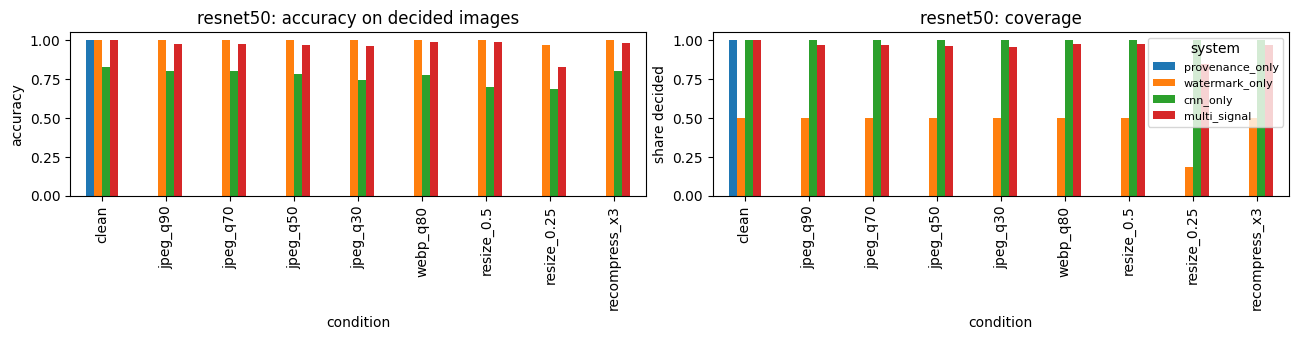

===== efficientnet_b0  (watermark P(AI|detected) = 0.9985, measured on validation)
coverage


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,1.0,0.4987,1.0,1.0000
jpeg_q90,0.0,0.4987,1.0,0.9642
jpeg_q70,0.0,0.4987,1.0,0.9652
jpeg_q50,0.0,0.4987,1.0,0.9706
jpeg_q30,0.0,0.4983,1.0,0.9699
webp_q80,0.0,0.4987,1.0,0.9763
resize_0.5,0.0,0.4987,1.0,0.9840
resize_0.25,0.0,0.1828,1.0,0.9469
recompress_x3,0.0,0.4987,1.0,0.9769


accuracy


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,1.0,1.0000,0.7945,1.0000
jpeg_q90,NaN,1.0000,0.7951,0.9719
jpeg_q70,NaN,1.0000,0.8065,0.9723
jpeg_q50,NaN,1.0000,0.8088,0.9697
jpeg_q30,NaN,1.0000,0.7978,0.9686
webp_q80,NaN,1.0000,0.7761,0.9808
resize_0.5,NaN,1.0000,0.6370,0.9929
resize_0.25,NaN,0.9707,0.5839,0.7459
recompress_x3,NaN,1.0000,0.8148,0.9791


f1


...

system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,0.0,0.0,0.0700,0.0000
jpeg_q90,NaN,0.0,0.0854,0.0575
jpeg_q70,NaN,0.0,0.0807,0.0566
jpeg_q50,NaN,0.0,0.0781,0.0617
jpeg_q30,NaN,0.0,0.0841,0.0639
webp_q80,NaN,0.0,0.0587,0.0385
resize_0.5,NaN,0.0,0.0260,0.0138
resize_0.25,NaN,1.0,0.0067,0.0135
recompress_x3,NaN,0.0,0.0574,0.0420


ece


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,0.01,0.0015,0.0858,0.0100
jpeg_q90,NaN,0.0015,0.0802,0.0055
jpeg_q70,NaN,0.0015,0.0781,0.0087
jpeg_q50,NaN,0.0015,0.0857,0.0087
jpeg_q30,NaN,0.0015,0.0853,0.0102
webp_q80,NaN,0.0015,0.1102,0.0109
resize_0.5,NaN,0.0015,0.2620,0.0113
resize_0.25,NaN,0.0278,0.3293,0.2094
recompress_x3,NaN,0.0015,0.0727,0.0090


fusion: share of images decided by each channel


,decided_by_provenance,decided_by_watermark,decided_by_cnn,coverage
condition,,,,
clean,1.0,0.0000,0.0000,1.0000
jpeg_q90,0.0,0.4987,0.4656,0.9642
jpeg_q70,0.0,0.4987,0.4666,0.9652
jpeg_q50,0.0,0.4987,0.4719,0.9706
jpeg_q30,0.0,0.4983,0.4716,0.9699
webp_q80,0.0,0.4987,0.4776,0.9763
resize_0.5,0.0,0.4987,0.4853,0.9840
resize_0.25,0.0,0.1828,0.7640,0.9469
recompress_x3,0.0,0.4987,0.4783,0.9769


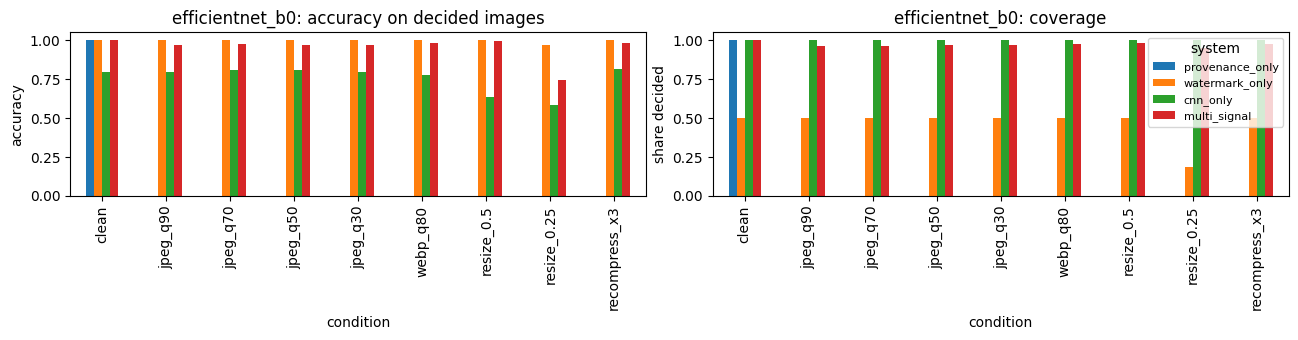

In [ ]:
import json, pandas as pd, matplotlib.pyplot as plt
SYSTEMS = ["provenance_only", "watermark_only", "cnn_only", "multi_signal"]
for arch in ARCHS:
    df = pd.read_csv(f"outputs/evaluation/{arch}/summary.csv")
    info = json.load(open(f"outputs/evaluation/{arch}/summary.json"))
    order = df.condition.unique()
    wc = info["watermark_confidence"]
    print(f"===== {arch}  (watermark P(AI|detected) = {wc['confidence']:.4f}, measured on validation)")
    for metric in ["coverage", "accuracy", "recall", "fpr", "f1", "ece"]:
        print(metric)
        display(df.pivot(index="condition", columns="system", values=metric).loc[order, SYSTEMS].round(4))
    print("fusion: share of images decided by each channel")
    display(df[df.system == "multi_signal"].set_index("condition")[["decided_by_provenance", "decided_by_watermark", "decided_by_cnn", "coverage"]].loc[order].round(4))
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
    df.pivot(index="condition", columns="system", values="accuracy").loc[order, SYSTEMS].plot.bar(ax=axes[0], ylim=(0, 1.05), legend=False)
    axes[0].set_title(f"{arch}: accuracy on decided images"); axes[0].set_ylabel("accuracy")
    df.pivot(index="condition", columns="system", values="coverage").loc[order, SYSTEMS].plot.bar(ax=axes[1], ylim=(0, 1.05))
    axes[1].set_title(f"{arch}: coverage"); axes[1].set_ylabel("share decided"); axes[1].legend(title="system", fontsize=8)
    plt.tight_layout(); plt.show()

## 6. Recompute the metrics from the saved per-image results (no GPU needed)
Recall and FPR are now counted over all AI / all human images. Before, FPR was computed only over the images a system decided,
which made the watermark's FPR read 1.0 at `resize_0.25` (it can only ever answer "AI", so it has no true negatives).
This step only rereads `per_image.csv`; it doesn't rerun any model. Then rerun section 5 to see the corrected tables.

In [4]:
for arch in ARCHS:
    !python scripts/evaluate.py --arch $arch --resummarize

Recomputed outputs/evaluation/resnet50/summary.csv and outputs/evaluation/resnet50/summary.json from outputs/evaluation/resnet50/per_image.csv (26928 rows)
Recomputed outputs/evaluation/efficientnet_b0/summary.csv and outputs/evaluation/efficientnet_b0/summary.json from outputs/evaluation/efficientnet_b0/per_image.csv (26928 rows)


## 7. Ablation: no watermark
Does the embedded watermark lower the CNN's accuracy? The CNN-only numbers in section 4 are below the stress test from notebook 02,
and the gap closes as JPEG compression erodes the watermark. This run leaves every image unmarked and switches the watermark channel off
(fusion = provenance → CNN). If the CNN-only results here match notebook 02's stress test, the watermark is what lowered them.
Results go to `thesis-data/evaluation/<model>_no_watermark/`. About as long as section 4.

In [5]:
for arch in ARCHS:
    !python scripts/evaluate.py --arch $arch --no-watermark

Evaluating 2992 images across 9 conditions on cuda; architecture=resnet50; provenance=on; watermark OFF (ablation: AI images unmarked)
== condition: clean
  provenance_only: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
   watermark_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
         cnn_only: coverage=1.000 acc=0.925 f1=0.923 fpr=0.050 ece=0.019
     multi_signal: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
== condition: jpeg_q90
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
         cnn_only: coverage=1.000 acc=0.902 f1=0.900 fpr=0.078 ece=0.023
     multi_signal: coverage=0.920 acc=0.927 f1=0.879 fpr=0.050 ece=0.019
== condition: jpeg_q70
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
         cnn_only: coverage=1.000 acc=0.847 f1=0.833 fpr=0.069 ece=0.051
     multi_signal: coverage=0.891 acc=0.875 f1=0.781 fpr

===== resnet50: CNN-only accuracy


,stress test (nb 02),"fusion run, AI marked","ablation, unmarked",watermark effect
condition,,,,
clean,0.9332,0.8262,0.9248,-0.0986
jpeg_q90,0.9021,0.8001,0.9024,-0.1023
jpeg_q70,0.8463,0.8018,0.8469,-0.0451
jpeg_q50,0.7934,0.7824,0.7948,-0.0124
jpeg_q30,0.7457,0.7470,0.7443,0.0027
webp_q80,0.8934,0.7774,0.8934,-0.1160
resize_0.5,0.8466,0.6965,0.8463,-0.1497
resize_0.25,0.7751,0.6892,0.7754,-0.0862
recompress_x3,0.8529,0.8011,0.8523,-0.0511


resnet50: CNN-only recall on AI images (human images are identical in both runs)


,AI marked,unmarked
condition,,
clean,0.7019,0.8995
jpeg_q90,0.6778,0.8828
jpeg_q70,0.6725,0.7629
jpeg_q50,0.6551,0.6798
jpeg_q30,0.5975,0.5921
webp_q80,0.6075,0.8399
resize_0.5,0.4253,0.7254
resize_0.25,0.4936,0.6664
recompress_x3,0.6577,0.7602


resnet50: fusion accuracy and coverage with and without the watermark channel


,fusion with watermark,fusion without watermark,coverage with,coverage without
condition,,,,
clean,1.0000,1.0000,1.0000,1.0000
jpeg_q90,0.9737,0.9270,0.9662,0.9205
jpeg_q70,0.9761,0.8754,0.9669,0.8907
jpeg_q50,0.9709,0.8279,0.9636,0.8760
jpeg_q30,0.9644,0.7797,0.9586,0.8676
webp_q80,0.9856,0.9286,0.9726,0.9084
resize_0.5,0.9908,0.8818,0.9783,0.8991
resize_0.25,0.8278,0.8170,0.8499,0.8346
recompress_x3,0.9831,0.8830,0.9719,0.8971


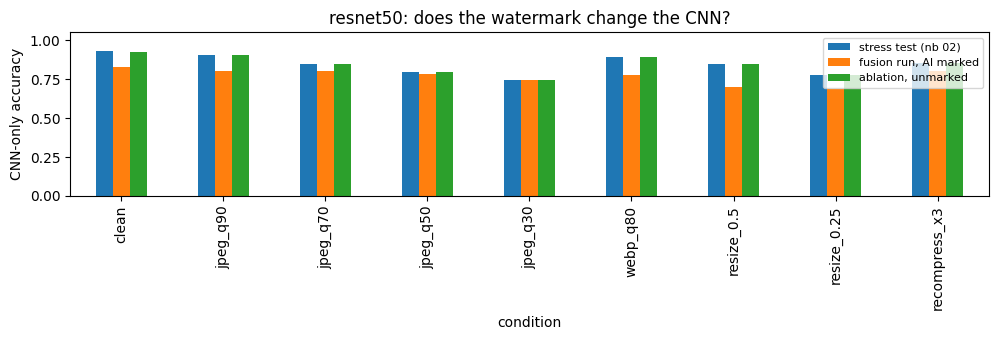

===== efficientnet_b0: CNN-only accuracy


,stress test (nb 02),"fusion run, AI marked","ablation, unmarked",watermark effect
condition,,,,
clean,0.9372,0.7945,0.9335,-0.1390
jpeg_q90,0.9188,0.7951,0.9188,-0.1237
jpeg_q70,0.8559,0.8065,0.8556,-0.0491
jpeg_q50,0.8239,0.8088,0.8239,-0.0150
jpeg_q30,0.7918,0.7978,0.7918,0.0060
webp_q80,0.8954,0.7761,0.8957,-0.1197
resize_0.5,0.8529,0.6370,0.8529,-0.2159
resize_0.25,0.6491,0.5839,0.6487,-0.0648
recompress_x3,0.8670,0.8148,0.8670,-0.0521


efficientnet_b0: CNN-only recall on AI images (human images are identical in both runs)


,AI marked,unmarked
condition,,
clean,0.6584,0.9370
jpeg_q90,0.6752,0.9230
jpeg_q70,0.6932,0.7917
jpeg_q50,0.6952,0.7254
jpeg_q30,0.6792,0.6671
webp_q80,0.6102,0.8500
resize_0.5,0.2987,0.7314
resize_0.25,0.1728,0.3027
recompress_x3,0.6865,0.7910


efficientnet_b0: fusion accuracy and coverage with and without the watermark channel


,fusion with watermark,fusion without watermark,coverage with,coverage without
condition,,,,
clean,1.0000,1.0000,1.0000,1.0000
jpeg_q90,0.9719,0.9464,0.9642,0.9225
jpeg_q70,0.9723,0.8931,0.9652,0.9007
jpeg_q50,0.9697,0.8528,0.9706,0.8971
jpeg_q30,0.9686,0.8288,0.9699,0.8900
webp_q80,0.9808,0.9278,0.9763,0.9068
resize_0.5,0.9929,0.8876,0.9840,0.8984
resize_0.25,0.7459,0.6667,0.9469,0.8954
recompress_x3,0.9791,0.8997,0.9769,0.9128


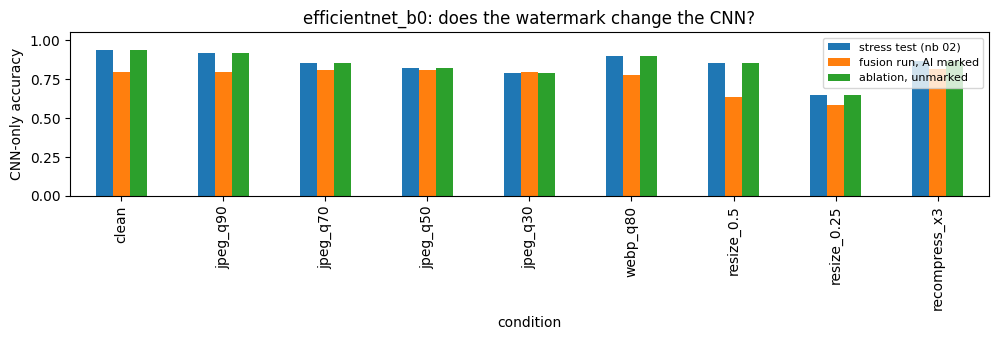

In [6]:
import pandas as pd, matplotlib.pyplot as plt
for arch in ARCHS:
    stress = pd.read_csv(f"outputs/stress_test/{arch}/results.csv").set_index("condition")
    marked = pd.read_csv(f"outputs/evaluation/{arch}/summary.csv")
    plain = pd.read_csv(f"outputs/evaluation/{arch}_no_watermark/summary.csv")
    order = marked.condition.unique()
    cnn = pd.DataFrame({
        "stress test (nb 02)": stress.loc[order, "accuracy"],
        "fusion run, AI marked": marked[marked.system == "cnn_only"].set_index("condition").loc[order, "accuracy"],
        "ablation, unmarked": plain[plain.system == "cnn_only"].set_index("condition").loc[order, "accuracy"],
    })
    cnn["watermark effect"] = cnn["fusion run, AI marked"] - cnn["ablation, unmarked"]
    print(f"===== {arch}: CNN-only accuracy")
    display(cnn.round(4))
    rec = pd.DataFrame({
        "AI marked": marked[marked.system == "cnn_only"].set_index("condition").loc[order, "recall"],
        "unmarked": plain[plain.system == "cnn_only"].set_index("condition").loc[order, "recall"],
    })
    print(f"{arch}: CNN-only recall on AI images (human images are identical in both runs)")
    display(rec.round(4))
    fus = pd.DataFrame({
        "fusion with watermark": marked[marked.system == "multi_signal"].set_index("condition").loc[order, "accuracy"],
        "fusion without watermark": plain[plain.system == "multi_signal"].set_index("condition").loc[order, "accuracy"],
        "coverage with": marked[marked.system == "multi_signal"].set_index("condition").loc[order, "coverage"],
        "coverage without": plain[plain.system == "multi_signal"].set_index("condition").loc[order, "coverage"],
    })
    print(f"{arch}: fusion accuracy and coverage with and without the watermark channel")
    display(fus.round(4))
    ax = cnn.drop(columns="watermark effect").plot.bar(figsize=(10, 3.5), ylim=(0, 1.05))
    ax.set_ylabel("CNN-only accuracy"); ax.set_title(f"{arch}: does the watermark change the CNN?"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()